# Dynamic NII, earnings at risk and EVaR under Hull-White and dynamic Nelson-Siegel scenarios

**Question:** if the bank's rates are not shocked once but simulated, how much net interest income does its book earn over the next 12 months, how much does a 200 basis point move change it, and how large are the earnings at risk and the economic value at risk of a Hull-White distribution once the Monte Carlo error is read beside them?

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 to 03 of this topic
- **Reading time:** about 50 minutes

## Objectives

By the end of this notebook you can:

- fit a Nelson-Siegel and a Svensson curve to the zero rates of a date, read their parameters and errors, and say what the dynamic Nelson-Siegel factors are;
- project the monthly net interest income (NII) of a book over 12 months under a constant balance sheet, with items that reset at different times and with a deposit beta;
- generate Hull-White one-factor short-rate scenarios and turn them into distributions of NII and EVE, and read earnings at risk (EaR) and economic value at risk (EVaR) with the Monte Carlo error of the quantile;
- explain why an EaR measured against a flat base can come out negative.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.irrbb import curves, eve_nii, shocks, simulation, slotting
from riskvalidation.validation import irrbb as rv_irrbb

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2


## Data

The data is case C14, the interest rate risk in the banking book (IRRBB) of the bank that failed in March 2023, as Contraste commits it: the FDIC call reports (FDIC BankFind financials, https://api.fdic.gov/banks/financials) and the US Treasury par curve (https://home.treasury.gov/resource-center/data-chart-center/interest-rates), public-domain sources of the licence class `mirror-allowed`. The bank is **real in aggregate and synthetic in behaviour**, so the repricing times, the deposit beta and the Hull-White mean reversion are stated or fitted by Contraste and labelled in the document. Money is in USD thousands, rates are decimals with continuous compounding, and a positive EaR, EVaR or delta NII is a loss.

- **Files read:** `data/derived/C14/vd-2022-q2.json` (`outputs.curve`, `dynamic_nii`, `ear_evar`, `balance_sheet`; `impact`), `vd-2021-q4.json` (`outputs.out_of_sample`, `curve`; `tests`) and `vd-2022-q4.json` (`outputs.curve`).
- **Not in the repository:** the quarterly history of the cost of deposits and of the Treasury curve, which the pipeline reads from the data root. Where the method needs a history of factors (Step 2), the notebook builds a **constructed, seeded** one and says so.

The next cell loads the three documents.

In [2]:
# Load the three valuation dates (the notebook sits three folders below the repository root) and the 19 midpoints
ROOT = Path("../../..").resolve()
derived = ROOT / "data" / "derived" / "C14"
quarters = ("2021-Q4", "2022-Q2", "2022-Q4")
docs = {q: json.loads((derived / f"vd-{q.lower()}.json").read_text(encoding="utf-8")) for q in quarters}
out = docs["2022-Q2"]["outputs"]
MID = slotting.bucket_grid().midpoints
LANG = "en"  # the bilingual fields of the documents are read in this language
NAME = {"base": "base", "parallel-up": "parallel up", "parallel-down": "parallel down"}
NAME.update({"asset": "asset", "liability": "liability", True: "yes", False: "no"})
print("valuation dates:", [d["outputs"]["valuation_date"] for d in docs.values()])

valuation dates: ['2021-12-31', '2022-06-30', '2022-12-31']


## Method

The method has five steps: (1) fit parametric curves, (2) the dynamic Nelson-Siegel factors and their forecast, (3) the monthly NII of the book, (4) Hull-White scenarios and the distributions of NII and EVE, (5) the out-of-sample check of the projection.

### Step 1: Nelson-Siegel and Svensson

A parametric curve describes the whole yield curve with a few numbers. The Nelson-Siegel curve gives the yield at maturity $m$ with four parameters, a level, a slope, a curvature and a decay $\tau$ (Nelson and Siegel, 1987, https://doi.org/10.1086/296409; dossier 05, D.5):

$$y(m) = \beta_0 + \beta_1\, \frac{1 - e^{-m/\tau}}{m/\tau} + \beta_2 \left( \frac{1 - e^{-m/\tau}}{m/\tau} - e^{-m/\tau} \right)$$

Svensson adds a second hump, $\beta_3 \left( \frac{1 - e^{-m/\tau_2}}{m/\tau_2} - e^{-m/\tau_2} \right)$ (Svensson, 1994, https://doi.org/10.3386/w4871). For a fixed $\tau$ the curve is linear in the betas, so the engine's `fit_nelson_siegel` solves least squares for each $\tau$ of a grid (0.25 to 10 years in steps of 0.25) and keeps the best; `fit_svensson` does a grid search over the two decays followed by a bounded polish, and nests Nelson-Siegel, so its error is never above. The next cell fits both to the 12 zero rates of 2022-06-30 and prints the parameters and the root mean square error in basis points.

Nelson-Siegel: β0 0.03131 β1 -0.02332 β2 0.00855 τ 0.25
    error (bp) 12.59
Svensson: β0 0.01526 β1 -0.00569 β2 0.04614 β3 0.05473
    τ1 0.608 τ2 11.472 | error (bp) 10.09
first value of the tau grid: 0.25
0.25 y: zero rates 0.01716 | Nelson-Siegel 0.01883 | Svensson 0.01842
20 y: zero rates 0.03445 | Nelson-Siegel 0.03113 | Svensson 0.03282


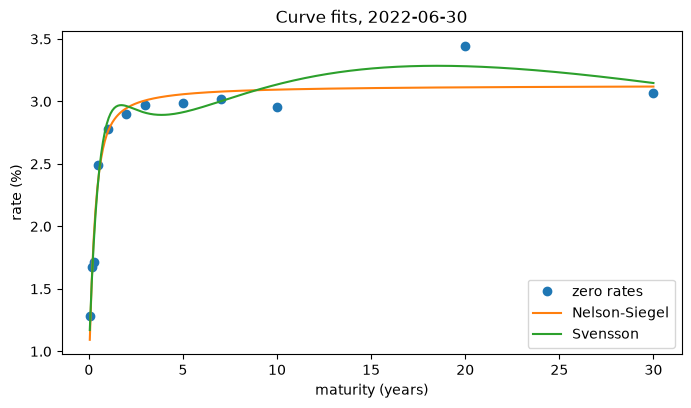

In [3]:
# Fit Nelson-Siegel and Svensson to the 12 zero rates of 2022-06-30 and draw the two curves
points = out["curve"]["points"]
tenors = np.array([p["tenor_years"] for p in points])
zero = np.array([p["zero_rate"] for p in points])
ns = curves.fit_nelson_siegel(tenors, zero)
sv = curves.fit_svensson(tenors, zero)
print(f"Nelson-Siegel: β0 {ns.beta0:.5f} β1 {ns.beta1:.5f} β2 {ns.beta2:.5f} τ {ns.tau:.2f}")
print(f"    error (bp) {ns.rmse * 1e4:.2f}")
print(f"Svensson: β0 {sv.beta0:.5f} β1 {sv.beta1:.5f} β2 {sv.beta2:.5f} β3 {sv.beta3:.5f}")
print(f"    τ1 {sv.tau1:.3f} τ2 {sv.tau2:.3f} | error (bp) {sv.rmse * 1e4:.2f}")
print("first value of the tau grid:", curves.DEFAULT_TAU_GRID[0])
ns_at = curves.nelson_siegel_yield(tenors, ns.beta0, ns.beta1, ns.beta2, ns.tau)
sv_at = curves.svensson_yield(tenors, sv.beta0, sv.beta1, sv.beta2, sv.beta3, sv.tau1, sv.tau2)
for k in (2, 10):
    print(f"{tenors[k]:g} y: zero rates {zero[k]:.5f} | Nelson-Siegel {ns_at[k]:.5f} | Svensson {sv_at[k]:.5f}")
grid = np.linspace(0.05, 30, 300)
ns_grid = curves.nelson_siegel_yield(grid, ns.beta0, ns.beta1, ns.beta2, ns.tau)
sv_grid = curves.svensson_yield(grid, sv.beta0, sv.beta1, sv.beta2, sv.beta3, sv.tau1, sv.tau2)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(tenors, zero * 100, "o", label="zero rates")
ax.plot(grid, ns_grid * 100, label="Nelson-Siegel")
ax.plot(grid, sv_grid * 100, label="Svensson")
ax.set_xlabel("maturity (years)")
ax.set_ylabel("rate (%)")
ax.set_title("Curve fits, 2022-06-30")
ax.legend()
plt.show()

Svensson follows the 12 points more closely than Nelson-Siegel, 10.09 bp against 12.59 bp of root mean square error, because its second hump can bend towards the 20-year point; the price is two more parameters. Both curves still miss that point (the zero rate of 3.445 percent against 3.113 and 3.282 percent) and the 3-month point (1.716 percent against 1.883 and 1.842 percent). The Nelson-Siegel decay is 0.25 years, the first value of its grid, so the best fit wants a faster decay than the grid allows and the result depends on the grid. A fitted curve is a model of the market curve, not the market curve, and the figure shows one day only.

### Step 2: dynamic Nelson-Siegel

Diebold and Li (2006, https://doi.org/10.1016/j.jeconom.2005.03.005) fix the decay and let the three betas move over time as a **level**, a **slope** and a **curvature** factor, each following an AR(1), which gives a forecasting model for whole curves. With the decay $\lambda = 0.0609$ per month and maturities $m$ in months, the loadings of the three factors are

$$y_t(m) = L_t + S_t\, \frac{1 - e^{-\lambda m}}{\lambda m} + C_t \left( \frac{1 - e^{-\lambda m}}{\lambda m} - e^{-\lambda m} \right), \qquad f_{t+1} = c + \phi\, f_t + \varepsilon_t$$

The paper says the decay was chosen to maximise the curvature loading at exactly 30 months; the engine documents that the maximum is at 29.446 months and that the paper rounds. The next cell checks it on a fine grid with the engine's own loadings, and then fits the three factors at each of the three committed dates by least squares on the tenors they share (`fit_dns_factors`). The level should rise through the 2022 hiking cycle.

λ = 0.0609 | curvature loading peaks at (months): 29.446
2021-Q4: level   0.02068 | slope  -0.02086 | curvature  -0.00942
2022-Q2: level   0.03095 | slope  -0.01271 | curvature   0.01523
2022-Q4: level   0.03837 | slope   0.00875 | curvature   0.00005


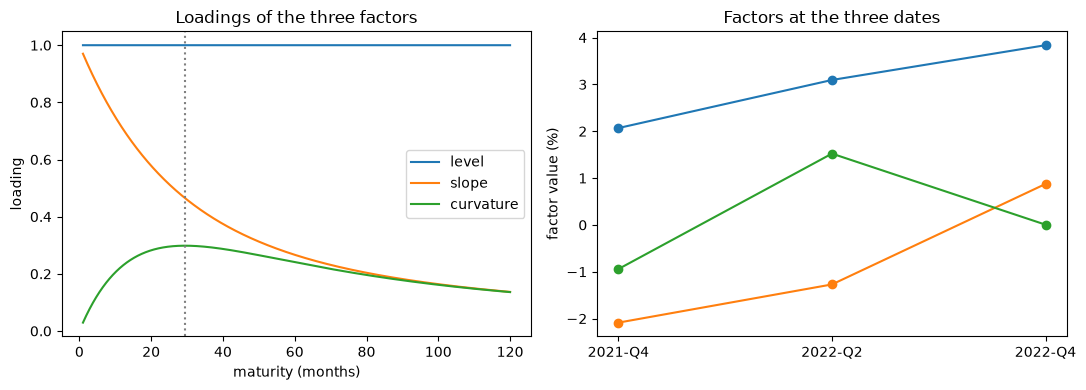

In [4]:
# Find the peak of the curvature loading on a fine grid, then fit the three factors at the three dates
fine = np.arange(1.0, 120.0, 0.001)
loadings = curves.dns_loadings(fine)
peak = float(fine[np.argmax(loadings[:, 2])])
print("λ =", curves.DIEBOLD_LI_LAMBDA, "| curvature loading peaks at (months):", round(peak, 3))
shared_years = np.array([0.25, 0.5, 1.0, 2.0, 3.0, 5.0, 7.0, 10.0, 20.0, 30.0])
months = np.round(shared_years * 12)
panel = []
for d in docs.values():
    by_tenor = {round(p["tenor_years"], 2): p["zero_rate"] for p in d["outputs"]["curve"]["points"]}
    panel.append([by_tenor[round(float(y), 2)] for y in shared_years])
factors = curves.fit_dns_factors(months, np.array(panel))
for q, f in zip(docs, factors):
    print(f"{q}: level {f[0]:9.5f} | slope {f[1]:9.5f} | curvature {f[2]:9.5f}")
names = ("level", "slope", "curvature")
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
for j, label in enumerate(names):
    left.plot(fine, loadings[:, j], label=label)
    right.plot(list(docs), factors[:, j] * 100, marker="o", label=label)
left.axvline(peak, color="grey", linestyle=":")
left.set_xlabel("maturity (months)")
left.set_ylabel("loading")
left.set_title("Loadings of the three factors")
left.legend()
right.set_ylabel("factor value (%)")
right.set_title("Factors at the three dates")
fig.tight_layout()
plt.show()

The left panel shows the three loadings: the level loading is flat at one, the slope loading decays from one to zero, and the curvature loading rises to a hump whose peak the dotted line marks at 29.446 months, not at the exactly 30 months the paper rounds to. The right panel shows the factors the hiking cycle moved: the level climbs from 2.07 to 3.10 and to 3.84 percent, and the slope goes from -2.09 to -1.27 and to +0.88 percent, which is the move from an upward-sloping curve to an inverted one. Three dates are too few to say anything about dynamics, which is why the forecast of the next step starts from a constructed history.

To forecast, the model needs a history of factors, at least four dates. The committed documents hold three dates only, and the pipeline's full history is not in the repository, so the next cell builds a **constructed, seeded history** of 48 months of AR(1) factors around the 2022-Q2 values, not data of the bank. It calls `forecast_dns_factors` (an AR(1) fitted to each factor by least squares, independent Gaussian innovations of the fitted residual variance, paths that start from the last row of the history and use nothing later) and `dns_scenarios` (the same paths through the loadings into yields at chosen maturities), and prints the spread of the 12-month-ahead level and of the 10-year yield.

factor paths (paths, months, factors): (2000, 12, 3)
level at month 12 (mean, 5th and 95th percentiles):
    [0.03122 0.02821 0.03415]
10-year yield at month 12 (mean, 5th and 95th percentiles):
    [0.03124 0.02804 0.03442]


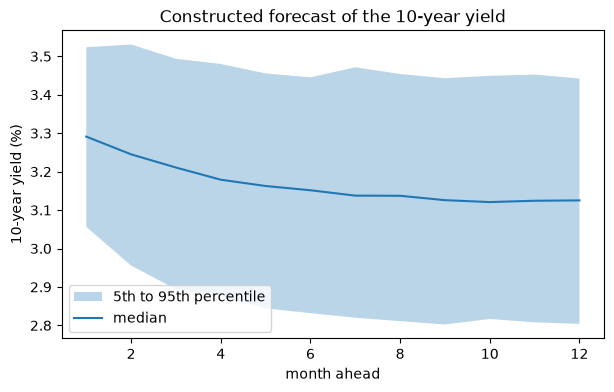

In [5]:
# A constructed, seeded factor history, the forecast of the factors and the yields at 12 months ahead
rng = np.random.default_rng(42)
center = factors[1]
history = np.zeros((48, 3))
history[0] = center
for t in range(1, 48):
    history[t] = center + 0.9 * (history[t - 1] - center) + rng.normal(0, [0.0015, 0.002, 0.003])
paths = curves.forecast_dns_factors(history, 12, 2000, 42)
yields = simulation.dns_scenarios(history, np.array([12.0, 60.0, 120.0]), 12, 2000, 42)
print("factor paths (paths, months, factors):", paths.shape)
level12, y10 = paths[:, -1, 0], yields[:, -1, 2]
print("level at month 12 (mean, 5th and 95th percentiles):")
print("   ", np.round([level12.mean(), *np.percentile(level12, [5, 95])], 5))
print("10-year yield at month 12 (mean, 5th and 95th percentiles):")
print("   ", np.round([y10.mean(), *np.percentile(y10, [5, 95])], 5))
ahead = np.arange(1, 13)
low, mid, high = (np.percentile(yields[:, :, 2], p, axis=0) * 100 for p in (5, 50, 95))
fig, ax = plt.subplots(figsize=(7, 4))
ax.fill_between(ahead, low, high, alpha=0.3, label="5th to 95th percentile")
ax.plot(ahead, mid, label="median")
ax.set_xlabel("month ahead")
ax.set_ylabel("10-year yield (%)")
ax.set_title("Constructed forecast of the 10-year yield")
ax.legend()
plt.show()

The band is the spread of 2,000 paths of the 10-year yield over the next 12 months: it opens roughly with the square root of time and ends between 2.80 and 3.44 percent around a mean of 3.12 percent. The factors are AR(1) series with independent innovations, so the band is symmetric and has the width the constructed noise gives it, nothing more. What the picture shows is how the function turns a history of factors into scenarios of whole curves; what it does not show is a forecast of the bank's rates, because the history it started from is made up and centred on the 2022-Q2 factors.

### Step 3: the monthly NII of the book

The dynamic NII projects the net interest income month by month over 12 months. Each interest-bearing item has a balance, a side (asset or liability), a current rate and a reset rule: after its reset month $k$ the item earns $\text{spread} + \beta\, r$, where $r$ is the short rate at the month of its latest reset and $\beta$ is the pass-through (1 for an asset indexed to the market, the deposit beta for a deposit). An item with $k = 0$ resets every month; an item with $k \ge 1$ keeps its current rate for the months before $k$ and then resets at $k, 2k, \dots$. The monthly NII is

$$NII_m = \frac{1}{12} \sum_i \text{side}_i\ B_i\, (1 + g)^{m/12}\ \text{rate}_{i,m}$$

with $g$ the annual growth of the balance sheet; $g = 0$ is the **constant balance sheet** of the standard (maturing and repricing flows replaced by identical new ones, BCBS d368 DIS70.5; dossier 05, D.6). The call report does not give the reset times, so the pipeline states them: 2 months for the band of three months or less, 8 months for three to twelve months, beyond the horizon for the rest (synthetic, in the document). The next cell lists the ten items of the 2022-Q2 projection.

In [6]:
# List the ten items of the dynamic NII with their balance, rate, spread, beta and reset month
dyn = out["dynamic_nii"]
items = dyn["items"]
print(dyn["balance_sheet_assumption"]["description"][LANG])
print("side | balance | rate | spread | beta | reset (months)")
for it in items:
    cols = [it["item_id"], NAME[it["side"]], f"{it['balance']:,.0f}", f"{it['rate0']:.4f}"]
    cols += [f"{it['spread']:.4f}", f"{it['beta']:.3f}", str(it["reprice_months"])]
    print(*cols, sep=" | ")

Constant balance sheet: maturing and repricing flows are replaced by identical new ones. Items not sensitive to rates (other assets, other liabilities) are left out; non-interest deposits stay at a zero rate.
side | balance | rate | spread | beta | reset (months)
D1 | asset | 14,808,000 | 0.0041 | -0.0087 | 1.000 | 0
D2 | asset | 55,065,000 | 0.0310 | 0.0182 | 1.000 | 2
D3 | asset | 3,777,000 | 0.0310 | 0.0182 | 1.000 | 8
D4 | asset | 12,019,000 | 0.0310 | 0.0310 | 0.000 | 120
D5 | asset | 50,000 | 0.0187 | 0.0059 | 1.000 | 2
D6 | asset | 556,000 | 0.0187 | 0.0059 | 1.000 | 8
D7 | asset | 121,338,000 | 0.0187 | 0.0187 | 0.000 | 120
D8 | liability | 116,177,000 | 0.0000 | 0.0000 | 0.000 | 0
D9 | liability | 73,976,000 | 0.0027 | 0.0017 | 0.075 | 0
D10 | liability | 3,703,000 | 0.0128 | 0.0000 | 1.000 | 0


The engine's `simulate_nii` takes the arrays of the items and a short-rate path of 12 to 36 months. The committed scenarios use a flat path: the short rate of the date (the zero rate of the second band) plus the shock, floored at zero (200 bp up, 200 bp down), kept for the 12 months. The next cell rebuilds the three paths with `apply_floor`, runs `simulate_nii` on each, and prints the total of each; in the same cell it runs the base path with a balance-sheet growth of 5 percent, which scales every month by $(1 + g)^{m/12}$, and draws the monthly NII of the four cases. The delta against the base is loss-positive: a negative number is a gain.

base             short rate 0.01279
    NII 12 months    4,297,741 | delta vs base            0
parallel up      short rate 0.03279
    NII 12 months    5,356,610 | delta vs base   -1,058,869
parallel down    short rate 0.00000
    NII 12 months    3,620,426 | delta vs base      677,315
NII 12 months with growth 5%: 4395363


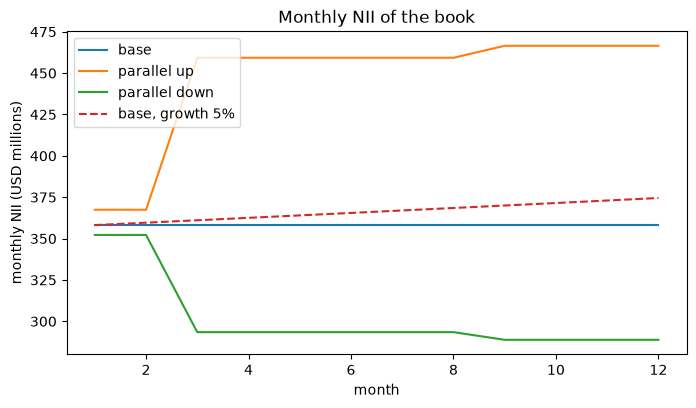

In [7]:
# Run the engine's simulate_nii on the three flat short-rate paths and on the base path with 5 percent growth
cols = {k: np.array([it[k] for it in items]) for k in ("balance", "rate0", "spread", "beta", "reprice_months")}
side = np.array([1 if it["side"] == "asset" else -1 for it in items])
args = (cols["balance"], side, cols["rate0"], cols["spread"], cols["beta"], cols["reprice_months"])
r0 = np.array(out["curve"]["zero_rates_at_midpoints"])
r_short = float(r0[1])
floor = out["scenarios"][0]["floor"]
result = {}
for key, bp in (("base", 0.0), ("parallel-up", 200.0), ("parallel-down", -200.0)):
    start = float(shocks.apply_floor(np.array([r_short]), np.array([bp]), floor)[0])
    result[key] = simulation.simulate_nii(*args, np.full(12, start), 0.0)
    delta = result["base"].total - result[key].total
    print(f"{NAME[key]:16s} short rate {start:.5f}")
    print(f"    NII 12 months {result[key].total:12,.0f} | delta vs base {delta:12,.0f}")
grown = simulation.simulate_nii(*args, np.full(12, r_short), 0.05)
print("NII 12 months with growth 5%:", round(grown.total))
fig, ax = plt.subplots(figsize=(8, 4.2))
for key in result:
    ax.plot(np.arange(1, 13), result[key].monthly_nii / 1e3, label=NAME[key])
ax.plot(np.arange(1, 13), grown.monthly_nii / 1e3, linestyle="--", label="base, growth 5%")
ax.set_xlabel("month")
ax.set_ylabel("monthly NII (USD millions)")
ax.set_title("Monthly NII of the book")
ax.legend()
plt.show()

The base NII is flat at 358 million a month because the short rate is held at 1.28 percent. The +200 bp line steps up at month 3, when the items that reset after 2 months take the new rate, and again at month 9 for the items that reset after 8; the -200 bp line steps down at the same months, only 128 bp because the zero floor stops the short rate at 0 percent. Over the 12 months the up shock is a gain of 1,058,869 and the down shock a loss of 677,315, and the dashed line shows 5 percent growth lifting every month by about 0.4 percent a month on top of the base. The picture shows one flat path per case, not a distribution: that comes next.

### Step 4: Hull-White scenarios, EaR and EVaR

A distribution of NII and EVE needs a distribution of rate paths. The Hull-White one-factor model has the short rate $r(t) = x(t) + \alpha(t)$ with $dx = -a\, x\, dt + \sigma\, dW$, $x(0) = 0$, and a deterministic part chosen to fit today's curve (Hull and White, 1990, https://doi.org/10.1093/rfs/3.4.573; the engine's form is the textbook one, Brigo and Mercurio, 2006, eq. 3.34):

$$\alpha(t) = f(0, t) + \frac{\sigma^2}{2 a^2}\, \left(1 - e^{-a t}\right)^2$$

with $f(0,t)$ the instantaneous forward rate of the initial curve. The engine's `hw1f_scenarios` simulates the monthly grid exactly and uses antithetic paths (the second half mirrors the first). The pipeline sets the mean reversion $a$ at 0.10 a year (stated, synthetic) and fits $\sigma$ to the daily changes of the 3-month Treasury yield over the last three years. For each path it computes the NII of the 12 months with `simulate_nii` and the EVE of the behavioural flows under the parallel shift implied by the path (the change of the short rate over the year, floored): that composition is the design of the product's pipeline, not an engine function. Then `ear_evar` takes the loss-positive difference between the base and the $(1 - \text{level})$ quantile:

$$EaR = NII_{base} - Q_{1-\text{level}}(NII), \qquad EVaR = EVE_{base} - Q_{1-\text{level}}(EVE)$$

The run of the product has 100,000 paths and seed 42. It takes a few seconds, so the next cell runs it and prints the 95 and 99 percent levels with their Monte Carlo error.

In [8]:
# Run the Hull-White scenarios: 100,000 antithetic paths, NII and EVE per path, EaR and EVaR with their error
dist = out["ear_evar"]
a_hw, sigma_hw = (p["value"] for p in dist["parameters"])
flows = np.zeros(19)
for it in out["balance_sheet"]["items"]:
    for row in it["cash_flows"]["behavioural"]:
        flows[row["bucket"] - 1] += row["amount"]
rates = simulation.hw1f_scenarios(zero, tenors, a_hw, sigma_hw, dist["horizon_months"], dist["n_paths"], dist["seed"])
nii_paths = np.array([simulation.simulate_nii(*args, q[:12], 0.0).total for q in rates])
shifts = (rates[:, -1] - rates[:, 0]) * 1e4
eve_paths = np.array([eve_nii.eve(flows, shocks.apply_floor(r0, np.full(19, s), floor), MID) for s in shifts])
base_nii, base_eve = result["base"].total, eve_nii.eve(flows, r0, MID)
print("a =", a_hw, "| σ =", round(sigma_hw, 6), "| paths and seed:", rates.shape[0], dist["seed"])
print("base NII and base EVE:", round(base_nii), round(base_eve))
main = {}
for lvl in (0.95, 0.99):
    got = simulation.ear_evar(nii_paths, eve_paths, base_nii, base_eve, lvl)
    err = simulation.ear_evar_mc_error(nii_paths, eve_paths, lvl, dist["n_batches"], antithetic=True)
    main[lvl] = (got, err)
    print(f"level {lvl:.2f}: EaR {got.ear:12,.0f} (±{err.ear_se:,.0f})")
    print(f"    EVaR {got.evar:12,.0f} (±{err.evar_se:,.0f})")

a = 0.1 | σ = 0.00504 | paths and seed: 100000 42
base NII and base EVE: 4297741 7036780
level 0.95: EaR     -585,961 (±995)
    EVaR    3,948,056 (±4,285)
level 0.99: EaR     -482,023 (±1,451)
    EVaR    4,370,301 (±6,623)


The EaR at both levels is **negative**: the NII at the 1 percent quantile is above the base NII. The base projection holds the short rate flat at today's 1.28 percent, while the Hull-White paths follow the forward curve, which at mid-2022 was upward-sloping, so the distribution of NII is centred well above the base. An EaR measured against a flat base therefore says that the earnings would be higher in 99 percent of the paths, not that there is no risk; the downside has to be read against the distribution's own centre. The next cell prints the mean and the quantiles of the paths and of the NII, and draws the two distributions.

short rate today and at month 12 (mean, 5th and 95th percentiles): 0.01279
    [0.02903 0.02117 0.03689]
NII of the 12 months: base, mean of the paths, 1st, 5th and 95th percentiles:
    4297741 5138757 [4779764. 4883702. 5393813.]
share of the paths with NII above the base: 1.0


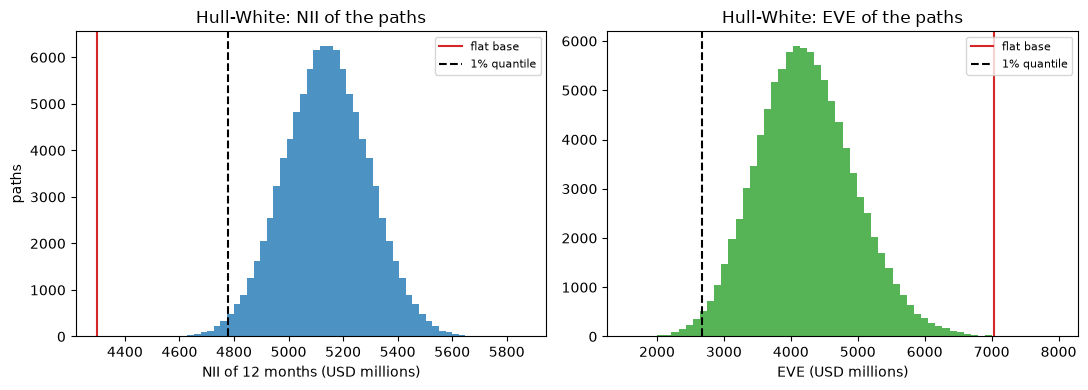

In [9]:
# Where the distribution sits against the flat base: the rates, the NII and the EVE of the paths
r12 = rates[:, -1]
today = round(float(rates[:, 0].mean()), 5)
print("short rate today and at month 12 (mean, 5th and 95th percentiles):", today)
print("   ", np.round([r12.mean(), *np.percentile(r12, [5, 95])], 5))
q_nii = np.percentile(nii_paths, [1, 5, 95])
print("NII of the 12 months: base, mean of the paths, 1st, 5th and 95th percentiles:")
print("   ", round(base_nii), round(float(nii_paths.mean())), np.round(q_nii))
print("share of the paths with NII above the base:", round(float((nii_paths > base_nii).mean()), 4))
q_eve = np.percentile(eve_paths, 1)
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
left.hist(nii_paths / 1e3, bins=60, color="tab:blue", alpha=0.8)
left.axvline(base_nii / 1e3, color="tab:red", label="flat base")
left.axvline(q_nii[0] / 1e3, color="black", linestyle="--", label="1% quantile")
left.set_xlabel("NII of 12 months (USD millions)")
left.set_ylabel("paths")
left.set_title("Hull-White: NII of the paths")
left.legend(fontsize=8)
right.hist(eve_paths / 1e3, bins=60, color="tab:green", alpha=0.8)
right.axvline(base_eve / 1e3, color="tab:red", label="flat base")
right.axvline(q_eve / 1e3, color="black", linestyle="--", label="1% quantile")
right.set_xlabel("EVE (USD millions)")
right.set_title("Hull-White: EVE of the paths")
right.legend(fontsize=8)
fig.tight_layout()
plt.show()

The left histogram sits wholly to the right of the red line: every one of the 100,000 paths earns more than the flat base, because the short rate of the paths has a mean of 2.90 percent at month 12 against 1.28 percent today. The 1 percent quantile, the dashed line, is therefore above the base and the EaR is negative; the honest reading is that earnings are not at risk against a base that stands still, and that the base is the weak side of the measure. The right histogram is the EVE, and here the dashed line is well below the red base: the EVaR of 4,370,301 at 99 percent is 62 percent of the base EVE of 7,036,780. The picture does not show the tail of a different model, only this one.

The second reading: the Monte Carlo error. The next cell repeats the run with 2,000 and 10,000 paths and prints each 99 percent estimate with its error, beside the 100,000 of the main run, and draws the error against the number of paths.

       paths       EaR 99    error      EVaR 99    error
       2,000     -480,611    7,071    4,305,713   30,669
      10,000     -480,337    5,715    4,356,301   22,474
     100,000     -482,023    1,451    4,370,301    6,623


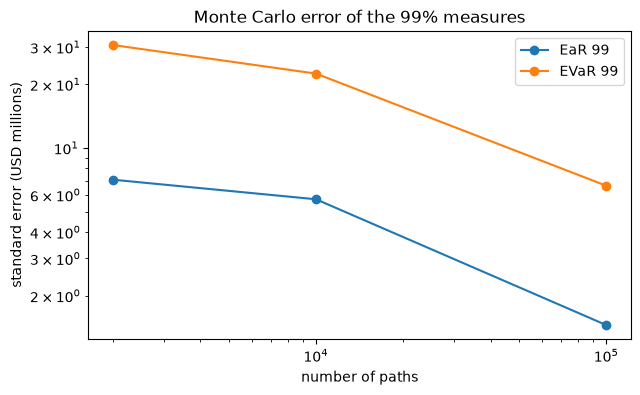

In [10]:
# The Monte Carlo error of the 99 percent EaR and EVaR with 2,000, 10,000 and 100,000 antithetic paths
g99, e99 = main[0.99]
rows_mc = [(dist["n_paths"], g99.ear, e99.ear_se, g99.evar, e99.evar_se)]
for n in (2000, 10000):
    sample = simulation.hw1f_scenarios(zero, tenors, a_hw, sigma_hw, 12, n, dist["seed"])
    nii_n = np.array([simulation.simulate_nii(*args, q[:12], 0.0).total for q in sample])
    shifts_n = (sample[:, -1] - sample[:, 0]) * 1e4
    eve_n = np.array([eve_nii.eve(flows, shocks.apply_floor(r0, np.full(19, s), floor), MID) for s in shifts_n])
    got = simulation.ear_evar(nii_n, eve_n, base_nii, base_eve, 0.99)
    err = simulation.ear_evar_mc_error(nii_n, eve_n, 0.99, dist["n_batches"], antithetic=True)
    rows_mc.append((n, got.ear, err.ear_se, got.evar, err.evar_se))
rows_mc.sort()
print(f"{'paths':>12s} {'EaR 99':>12s} {'error':>8s} {'EVaR 99':>12s} {'error':>8s}")
for n, ear, ear_se, evar, evar_se in rows_mc:
    print(f"{n:12,d} {ear:12,.0f} {ear_se:8,.0f} {evar:12,.0f} {evar_se:8,.0f}")
fig, ax = plt.subplots(figsize=(7, 4))
ax.loglog([r[0] for r in rows_mc], [r[2] / 1e3 for r in rows_mc], marker="o", label="EaR 99")
ax.loglog([r[0] for r in rows_mc], [r[4] / 1e3 for r in rows_mc], marker="o", label="EVaR 99")
ax.set_xlabel("number of paths")
ax.set_ylabel("standard error (USD millions)")
ax.set_title("Monte Carlo error of the 99% measures")
ax.legend()
plt.show()

Both errors fall as the number of paths grows, from about 30 million dollars of EVaR error at 2,000 paths to under 7 million at 100,000, and the slope on the log-log axes is gentler than the minus one half of independent draws, because the error is itself estimated from 20 batches and antithetic pairs change the constant. The estimates themselves stay within a few errors of each other, so 2,000 paths already place the 99 percent EVaR within about 2 percent of the 100,000-path figure. The picture shows the error of a quantile, which is larger than the error of a mean at the same sample size; the engine returns it beside the estimate so that the validator reads both.

### Step 5: the out-of-sample check

A projection earns trust by being compared with what happened. The projection made at 2021-12-31 for a +200 bp shock (the loss-positive change in NII over 12 months) can be compared with the change in NII the bank realised in 2022 from the call reports. The engine's test `irrbb.nii_out_of_sample` takes the projected and the realised change and returns the relative error with a light (green at most 10 percent, amber at most 25 percent, red above: Contraste internal gates). The valuation dates of 2022-06-30 and 2022-12-31 have no realised year after them, because the bank failed on 2023-03-10 and filed no later report: the document says so and the test returns `not_evaluated` rather than a number. The next cell runs the test on the 2021-Q4 pair, draws the projected and the realised change, then prints the reason the other two dates give.

2021-Q4: projected delta NII (loss positive) -1,138,367
realised -1,358,000
relative error 0.1617 | difference in money 219,633
2022-Q2 not evaluated: No realised year follows this date in the call reports: the bank failed on 2023-03-10 and filed no later report, so the 12-month projection cannot be compared with a realised one.
2022-Q4 not evaluated: No realised year follows this date in the call reports: the bank failed on 2023-03-10 and filed no later report, so the 12-month projection cannot be compared with a realised one.


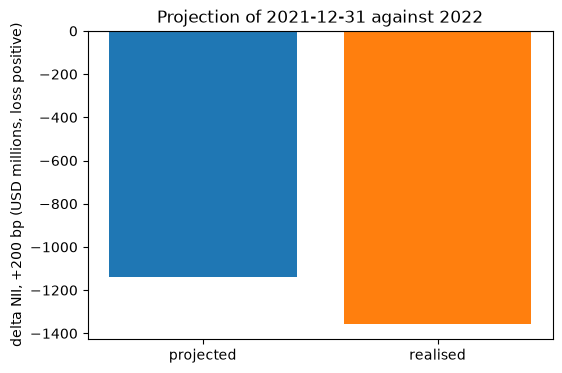

In [11]:
# Run the out-of-sample test on the 2021-Q4 projection and show why the other two dates are not evaluated
oos = docs["2021-Q4"]["outputs"]["out_of_sample"]
test_oos = rv_irrbb.nii_out_of_sample(oos["projected_delta_nii"], oos["realised_delta_nii"])
projected, realised = oos["projected_delta_nii"], oos["realised_delta_nii"]
print(f"2021-Q4: projected delta NII (loss positive) {projected:,.0f}")
print(f"realised {realised:,.0f}")
print(f"relative error {test_oos.statistic:.4f} | difference in money {test_oos.metric:,.0f}")
for q in ("2022-Q2", "2022-Q4"):
    print(q, "not evaluated:", docs[q]["outputs"]["out_of_sample"]["reason"][LANG])
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(["projected", "realised"], [projected / 1e3, realised / 1e3], color=["tab:blue", "tab:orange"])
ax.axhline(0, color="grey", linewidth=0.8)
ax.set_ylabel("delta NII, +200 bp (USD millions, loss positive)")
ax.set_title("Projection of 2021-12-31 against 2022")
plt.show()

The two bars are both negative, which in this loss-positive convention means both are gains: the projection for +200 bp said that the bank would earn 1.14 billion dollars more, and the realised change of 2022 was a gain of 1.36 billion, a relative error of 16.2 percent. It compares a shock with a path, so it checks the order of magnitude and the sign of the sensitivity, not the forecast. The other two dates have no realised year because the bank failed on 2023-03-10 and filed no later report; the test says so with its reason and returns no number, which is what the print above lists. The picture is a single comparison, not a backtest series.

## Results

**Answer:** over the next 12 months the book earns a base NII of 4,297,741 (USD thousands) with the short rate held at 1.28 percent; a +200 bp move lifts it by 1,058,869 and a -200 bp move, stopped by the zero floor, lowers it by 677,315. Under 100,000 Hull-White paths the EaR is -482,023 at 99 percent, negative because every path earns more than the flat base, and the EVaR is 4,370,301 at 99 percent, with a Monte Carlo error of 6,623.

- **The curve fits.** Nelson-Siegel fits the 12 zero rates of 2022-06-30 with an error of 12.59 bp and Svensson with 10.09 bp, so the second hump buys 2.5 bp. Both miss the 20-year point and the short end. The Nelson-Siegel decay is 0.25 years, the lowest value of its grid, so a validator should widen the grid before trusting the betas.
- **Dynamic Nelson-Siegel.** The curvature loading peaks at 29.446 months with the decay of 0.0609, not at the exactly 30 the paper rounds to. The level rises from 2.07 to 3.10 and to 3.84 percent across the three dates, and the slope from -2.09 to -1.27 and to +0.88 percent. The forecast comes from a constructed history, so its spread (the 12-month level between 2.82 and 3.42 percent) shows how the function works and says nothing about the bank.
- **The monthly NII.** The items that reset every month move at once, the 2-month items from month 3 and the 8-month items from month 9. The signs are the opposite of notebook 01's repricing gap, which gave a loss of 199,057 for +100 bp: the gap treats the part of the deposits it places overnight as repricing at the full shock, while the projection gives the interest-bearing deposits a beta of 0.075 and the non-interest-bearing ones none. The earnings effect of a rate rise is as much a statement about the deposit beta as about the book. A 5 percent growth gives 4,395,363 over the 12 months.
- **EaR and EVaR.** The EaR is -585,961 at 95 percent and -482,023 at 99 percent, and the EVaR is 3,948,056 and 4,370,301. The short rate has a mean of 2.90 percent at month 12 against 1.28 percent today, since Hull-White follows the forward curve, and the mean NII of the paths is 5,138,757, 20 percent above the base. The EVaR of 4,370,301 is 62 percent of the base EVE of 7,036,780.
- **The Monte Carlo error.** The 99 percent EVaR is 4,305,713 with 2,000 paths (error 30,669), 4,356,301 with 10,000 (22,474) and 4,370,301 with 100,000 (6,623). The error falls with the number of paths, though not smoothly, and the estimates stay within a few errors of the main run.
- **The out-of-sample check.** At 2021-12-31 the projection for +200 bp was a change of -1,138,367 (a gain) against a realised change of -1,358,000 in 2022: a relative error of 0.1617. At 2022-06-30 and 2022-12-31 there is no realised year, and the test is `not_evaluated` with the reason written, never a number.
- **What the notebook does not show.** The fit of the pass-through to the bank's history and the stability of the replicating weights (notebook 05), the three-date comparison with the gap and duration approximations (notebook 07), and any forecast of the bank's real rates: the history of factors is constructed.

## Summary

- A parametric curve compresses a yield curve into four or six numbers; Svensson nests Nelson-Siegel and never fits worse, and the Nelson-Siegel decay can sit on the edge of its grid.
- The dynamic Nelson-Siegel makes the three factors AR(1) series and turns a history of factors into scenarios of whole curves; here the history is constructed, because the bank's quarterly history is not in the repository.
- The monthly NII of the book depends on when each item resets and on the deposit beta; the constant balance sheet is the standard's assumption.
- EaR and EVaR are quantile differences from simulated paths, with a Monte Carlo error that falls with the number of paths; an EaR against a flat base can be negative when the scenarios follow an upward forward curve.
- A projection is compared with the realised year when there is one; the bank filed no later report, so two of the three dates have none, and the engine says so instead of returning a number.

**What to try next.** Change the mean reversion `a_hw` and watch how the spread of the 12-month rate moves the EVaR more than the EaR. Then continue with notebook 05, the validation tests.

## References

- Nelson, C. R. and Siegel, A. F. (1987), Parsimonious modeling of yield curves, Journal of Business 60(4). https://doi.org/10.1086/296409
- Svensson, L. E. O. (1994), Estimating and interpreting forward interest rates: Sweden 1992-1994, NBER Working Paper 4871. https://doi.org/10.3386/w4871
- Diebold, F. X. and Li, C. (2006), Forecasting the term structure of government bond yields, Journal of Econometrics 130(2). https://doi.org/10.1016/j.jeconom.2005.03.005
- Hull, J. and White, A. (1990), Pricing interest-rate-derivative securities, Review of Financial Studies 3(4). https://doi.org/10.1093/rfs/3.4.573
- Brigo, D. and Mercurio, F. (2006), Interest Rate Models, Theory and Practice, Springer (equation 3.34, as cited by the engine; the edition is not verified).
- BCBS (2016), d368, Standards: Interest rate risk in the banking book, DIS70.5 (the constant balance sheet). https://www.bis.org/bcbs/publ/d368.htm
- BCBS, Standards: Interest rate risk in the banking book, SRP31. https://www.bis.org/basel_framework/chapter/SRP/31.htm
- FDIC, BankFind financials, public domain. https://api.fdic.gov/banks/financials
- US Department of the Treasury, Daily Treasury Par Yield Curve Rates, public domain. https://home.treasury.gov/resource-center/data-chart-center/interest-rates
- Dossier 05 of the Contraste research, sections C.4, D.5 and D.6.